# **Week 6 Lab** <br/> Practical SIFT Application
## Task 1
1. Open the image TowerFull.jpg using an image editor (Paint).
2. Select the left side about 2/3 of image, crop it and save it as TowerRight.jpg.
3. Re-open the image TowerFull.jpg using an image editor (Paint).
4. Select the right side about 2/3 of image, crop it and save it as TowerLeft.jpg.

    No need to resize images, TowerRight.jpg & TowerLeft.jpg, because vertically they are of same dimensions.

5. Upload these images in Jupyter-Lab or in the current folder. In the code (Image_Stitching.ipynb), ensure proper naming of Left and Right Images:

    ```python
    image1 = cv2.imread('TowerLeft.jpg')
    image2 = cv2.imread('TowerRight.jpg')
    ```

6. Run/Execute the program and view the output results.

    This is the easiest and most efficient way to test image stitching using SIFT, because we have generated the left and right images manually from an original source image.

7. Repeat the above and test with two other sample images: `CafetariaFull.jpg` & `AgriBuildingFull.jpg`.

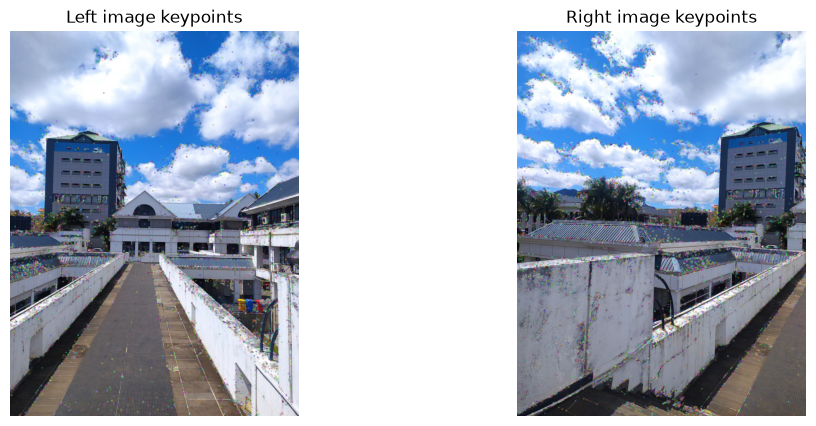

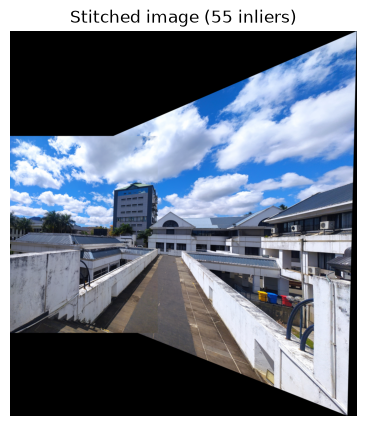

In [7]:
# Import the libraries used for image reading, feature detection, and visualization.
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the two overlapping images from the notebook's Images directory.
# These images represent adjacent parts of the same scene and will be aligned.
image1 = cv2.imread('Images/BridgeRight1.jpg')
image2 = cv2.imread('Images/BridgeLeft1.jpg')

# Stop with a clear error if either image could not be read.
if image1 is None or image2 is None:
    raise FileNotFoundError(f'Could not load {image1} or {image2}')

# Convert both images to grayscale because SIFT works on single-channel intensity images.
image1_gray = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
image2_gray = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

# Detect keypoints and descriptors in both images using the SIFT feature extractor.
sift = cv2.SIFT_create()
keypoint1, descriptor1 = sift.detectAndCompute(image1_gray, None)
keypoint2, descriptor2 = sift.detectAndCompute(image2_gray, None)

# Ensure the algorithm actually found descriptors before matching.
if descriptor1 is None or descriptor2 is None:
    raise RuntimeError('SIFT could not find descriptors in both images')

# Draw the detected SIFT keypoints on the original images for inspection and saving.
keypoints_image1 = cv2.drawKeypoints(image1, keypoint1, None)
keypoints_image2 = cv2.drawKeypoints(image2, keypoint2, None)
cv2.imwrite('orig_img_lft_keypnts.jpg', keypoints_image1)
cv2.imwrite('orig_img_rght_keypnts.jpg', keypoints_image2)

# Visualize the keypoints found in each image side by side.
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(keypoints_image1, cv2.COLOR_BGR2RGB))
plt.title('Left image keypoints')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(keypoints_image2, cv2.COLOR_BGR2RGB))
plt.title('Right image keypoints')
plt.axis('off')
plt.show()

# Match descriptors and retain the best ratio-tested match from each pair.
# This keeps only strong correspondences and rejects ambiguous matches.
flann = cv2.FlannBasedMatcher(
    dict(algorithm=1, trees=5),
    dict(checks=1000)
)
matched_features = flann.knnMatch(descriptor1, descriptor2, k=2)
good_matches = [
    pair[0]
    for pair in matched_features
    if len(pair) == 2 and pair[0].distance < 0.25 * pair[1].distance
]

# Require enough robust matches before estimating the geometric transformation.
if len(good_matches) < 4:
    raise RuntimeError(f'Not enough reliable matches for homography: {len(good_matches)} found')

# Estimate the transformation from the left image into the right image.
# A homography models the perspective change between the two views.
init = np.float32([keypoint1[match.queryIdx].pt for match in good_matches]).reshape(-1, 1, 2)
goal = np.float32([keypoint2[match.trainIdx].pt for match in good_matches]).reshape(-1, 1, 2)
H, inlier_mask = cv2.findHomography(init, goal, cv2.RANSAC, 9.0)

# If homography estimation fails, no reliable stitching can be computed.
if H is None:
    raise RuntimeError('Homography estimation failed')

# Build a canvas that contains both transformed left and original right images.
# The canvas is large enough to include both images after alignment.
height1, width1 = image1.shape[:2]
height2, width2 = image2.shape[:2]
left_corners = np.float32([
    [0, 0], [width1, 0], [width1, height1], [0, height1]
]).reshape(-1, 1, 2)
right_corners = np.float32([
    [0, 0], [width2, 0], [width2, height2], [0, height2]
]).reshape(-1, 1, 2)
warped_left_corners = cv2.perspectiveTransform(left_corners, H)
all_corners = np.concatenate((warped_left_corners, right_corners), axis=0)

# Compute the minimum extents so the stitched output can be positioned correctly.
xmin, ymin = np.floor(all_corners.min(axis=0).ravel()).astype(int)
xmax, ymax = np.ceil(all_corners.max(axis=0).ravel()).astype(int)
translation = np.array([
    [1, 0, -xmin],
    [0, 1, -ymin],
    [0, 0, 1]
], dtype=np.float64)
canvas_size = (xmax - xmin, ymax - ymin)

# Warp the left image into the shared canvas using the estimated homography.
warped_left = cv2.warpPerspective(image1, translation @ H, canvas_size)
final = warped_left.copy()

# Warp the right image into the same canvas and overwrite only the pixels that belong to it.
# This combines both images into a single stitched panorama.
right_warped = cv2.warpPerspective(image2, translation, canvas_size)
right_mask = np.any(right_warped != 0, axis=2)
final[right_mask] = right_warped[right_mask]

# Save the final composited result and show it to the user.
cv2.imwrite('Stitched_Image.jpg', final)

plt.figure(figsize=(12, 5))
plt.imshow(cv2.cvtColor(final, cv2.COLOR_BGR2RGB))
plt.title(f'Stitched image ({int(inlier_mask.sum())} inliers)')
plt.axis('off')
plt.show()

## Task 2 (Image_Stitching.ipynb)

1. Test and run the program again using another pair of images
(`ZurichImageA.jpg` & `ZurichImageB.jpg`)

2. Determine which image (`ZurichImageA.jpg` & `ZurichImageB.jpg`) is Left view and Right view for proper stitching.

3. Check the dimensions of the two images m x n pixels.
    > 600 x 448 px

4. Upload these images in Jupyter-Lab or in the current folder.

5. In the code (Image_Stitching.ipynb), ensure proper naming of
Left and Right Images

    ```python
    image1 = cv2.imread('ImageNameleft.jpg')
    image2 = cv2.imread('ImageNameright.jpg')
    ```

6. Run/Execute the program, view output results.

7. Use a camera take two pictures of a building on campus, 1st
picture capturing leftward view of building and 2nd picture the rightward view of the building. The two pictures must be taken with just a slight shift (panning) of the camera.

8. Resize the two pictures if needed.

9. Repeat the image stitching experiment as previously done.

10. What difficulties and issues did you encounter when taking two photos with your camera to apply stitching?
    > - Slight camera rotation can cause misalignment
    > - Moving objects/people cause motion blur leading to inconsistent keypoints
    > - Parallax and perspective differences result in objects at different depths shifting by different amounts
    > - Change in lighting, reflections or shadows can make feature matching unreliable
